# OPERA DISP-S1, part 1: Faults and landslides in East San Francisco Bay

**Author**: Original notebook by Scott Staniewicz, for the August 3-7, 2026 [EarthScope InSAR Short Course (ISCE+)](https://www.earthscope.org/event/2026-technical-course-insar-processing-and-analysis-isce/).

Modified for the Hayward Fault by Eric Fielding for the November 12, 2026 ARSET Training.
      
The Hayward Fault is a major active fault that runs through the east side of the San Francisco Bay, an is part of the plate boundary deformation along with the San Andreas Fault to the west of the SF Bay. It is considered one of the two most hazardous faults in California because it has accumulated enough stress to rupture in a magnitude 6.5 to 6.8 earthquake and it is within or next to densely populated areas from Fremont and Hayward through Oakland and Berkeley.

There are numerous landslides in the East Bay Hills and adjacent areas. A set of four landslides in the Berkeley Hills have been moving gradually for decades and are covered with homes.

We will measure that with **OPERA DISP-S1** (Level-3 Surface Displacement from Sentinel-1),
produced by JPL and distributed by the ASF DAAC.

This notebook works with **DISP-S1 frame 11115** acquired from 2022 to 2026

What you need to know about the product:

- **Frame-based.** A frame is a fixed footprint on the ground that does not move between
  acquisitions, so the stack lines up pixel-for-pixel with no coregistration on your part.
- **Geocoded** onto a 30 m UTM grid (different frames can be in different UTM zones).
- **Line-of-sight displacement in meters**, positive meaning *towards* the satellite.
- **Chunked NetCDF4/HDF5**, so an S3 client can read a small spatial window without
  transferring the whole file.
- **The reference date moves forward in time.** It must be handled before the measurements
  can be interpreted as one continuous time series.

---
By the end you will have a rebased displacement stack over East San Francisco Bay, ready for MintPy in part 2.

# Load required modules

### Adjusting the OpenScienceLab kernel

If running from an ASF OpenScienceLab server, the following statement can be used to add the necessary modules.

In [1]:
#%pip install --upgrade dolphin "zarr>=3" rioxarray \
#  "opera-utils[asf,disp,geopandas,tropo] @ git+https://github.com/scottstanie/opera-utils.git@develop-scott"

You may need to restart the kernel, and then this will work!

In [2]:
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

import opera_utils
from opera_utils import Bbox, disp

%matplotlib inline

## Finding a DISP-S1 frame to cover the East Bay

DISP-S1 is indexed by frame ID, so the first job is turning a place into a frame.

You can click around on the [ASF displacement portal](https://displacement.asf.alaska.edu/), check the "Frame ID" that comes up for the ascending (or descending) pass.
However, it can be easier to ask `opera-utils` directly.

In [3]:
# Hayward Fault and SF Bay area, California
AOI_BBOX = Bbox(left=-122.5, bottom=37.0, right=-121.5, top=38.0)

frames = opera_utils.get_intersecting_frames(AOI_BBOX)
for feature in frames["features"]:
    print(f"frame {feature['id']:>6s}  {feature['properties']['orbit_pass']}")

frame   9156  ASCENDING
frame   9157  ASCENDING
frame  11115  DESCENDING
frame  11116  DESCENDING
frame  30714  DESCENDING
frame  30715  DESCENDING
frame  36542  ASCENDING
frame  36543  ASCENDING


Several frames overlap the AOI, because ascending and descending tracks both see this area.
In this notebook, we will use the ascending frame **9157**.

A frame only covers part of the valley, so if your own area of interest straddles two frames you should process each one separately and mosaic afterwards. 

You can also try to stitch corresponding dates together before fitting a velocity, but note that not all adjacent frames have the same dates.
More details of how the S1 bursts were chosen in in the Burst DB repo: https://github.com/opera-adt/burst_db/tree/main/scripts/historical_bursts

In [4]:
FRAME_ID = 11115

products = disp.search(frame_id=FRAME_ID)
print(f"{len(products)} products available")
print(
    f"spanning {products[0].secondary_datetime.date()} to {products[-1].secondary_datetime.date()}"
)
print(f"full frame is {products[0].shape} pixels (~450 MB per granule)")

374 products available
spanning 2016-09-03 to 2026-03-21
full frame is (6866, 9598) pixels (~450 MB per granule)


## Referencing  moving reference date

Each DISP-S1 granule holds the displacement between a reference date and a secondary date. If the reference date were fixed for all time, every granule would already be a cumulative displacement map and there would be nothing else to do.

However, due to tradeoffs/limitations for the production data system, the granules were produced with a moving reference frame. That is, each batch that OPERA processes is run in **ministacks** of up to ~15 acquisitions: within one ministack the reference is held constant, and then it jumps forward to start the next one.
Plotting reference date against secondary date shows the structure immediately.

/var/folders/qb/67x8tf7116qf7cpmq_gs6_2m0000gq/T/ipykernel_14882/3695666720.py:2: UserWarning: no explicit representation of timezones available for np.datetime64
  ref_dates = np.array(stack.reference_dates, dtype="datetime64[s]")
/var/folders/qb/67x8tf7116qf7cpmq_gs6_2m0000gq/T/ipykernel_14882/3695666720.py:3: UserWarning: no explicit representation of timezones available for np.datetime64
  sec_dates = np.array(stack.secondary_dates, dtype="datetime64[s]")


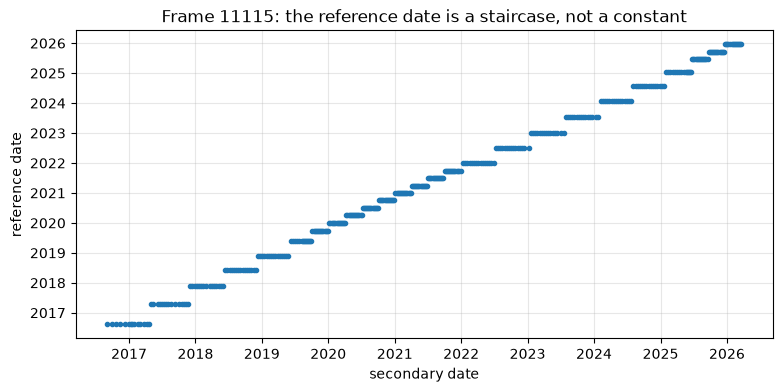

In [5]:
stack = disp.DispProductStack(products)
ref_dates = np.array(stack.reference_dates, dtype="datetime64[s]")
sec_dates = np.array(stack.secondary_dates, dtype="datetime64[s]")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(sec_dates, ref_dates, "o", ms=3)
ax.set_xlabel("secondary date")
ax.set_ylabel("reference date")
ax.set_title(f"Frame {FRAME_ID}: the reference date is a staircase, not a constant")
ax.grid(alpha=0.3)

Every horizontal line is one "ministack" (in the nomenclature of `dolphin`). Due to how the OPERA data system was set up, the reference jumps to the last date of the previous ministack.

If you naively stack the `displacement` layers and plot one pixel, your plot looks like a sawtooth, where the series resets towards zero at every ministack boundary. To recover a continuous time series you have to add the accumulated displacement of all preceding ministacks.

A general way to solve this would be to do a "network inversion" like MintPY has; however, we know this is a simple daisy chain, so we can do a simple cumulative sum.

A practical consequence: you can request any date window you like. There is no need to start or stop on a ministack boundary, because rebasing handles a partial ministack the same way it handles a whole one.

While this is a minor annoyance, this does offer the benefit that if a time period (say the period of 2014-2019) led to especially high decorrelation for a region, you can still download and process the later periods that are less noisy and not worry about all pixels being masked.

# Download a subset

`opera-utils disp-s1-download` searches, downloads and crops in one step. The crop happens
before anything is written to disk, so you get ~11 MB per date instead of ~450 MB.

**On OpenScienceLab, always pass `--url-type S3`.** OSL runs in the same AWS region as the
ASF archive, so S3 reads only the bytes of your AOI. Over HTTPS the whole 450 MB granule is
pulled down first and then cropped, which is roughly 10x slower.

If you are running this on a local computer or other server outside of AWS, then you have to use **`--url-type HTTPS`**.

In [6]:
!mkdir -p subsets

We take 2022 through March 2026: 150 granules across 14 ministacks, about 2 GB cropped. That
window includes part of the 2022 and 2025-2026 droughts and the
2023 atmospheric-river winter that had increased rainfall.

In [9]:
%%bash
time opera-utils disp-s1-download \
    --frame-id 11115 \
    --bbox -122.4 37.75 -122.1 38.05 \
    --start-datetime 2022-01-01 \
    --end-datetime 2026-03-27 \
    --url-type HTTPS \
    --num-workers 8 \
    --output-dir subsets

Found 150 urls for Frame 11115
Subsetting to Rows: slice(1675, 2777, None), cols: slice(973, 1862, None)
100%|██████████| 150/150 [00:02<00:00, 58.81it/s]

real	0m7.425s
user	0m18.018s
sys	0m6.375s


### Verify download completeness

Transient archive errors can leave an incomplete final ministack without causing a later
processing error. During testing, separate runs stopped on an Earthdata `403 Forbidden`
and an ASF `502 Bad Gateway`.

If the counts differ, run the download command again. Existing files are skipped.

In [10]:
expected = disp.search(
    frame_id=FRAME_ID,
    start_datetime=datetime(2022, 1, 1),
    end_datetime=datetime(2026, 3, 27),
)
downloaded = sorted(Path("subsets").glob("OPERA*.nc"))
print(f"on disk: {len(downloaded)}   expected: {len(expected)}")
assert len(downloaded) == len(expected), "Incomplete download - re-run the cell above"

on disk: 150   expected: 150


## Check on downloaded granules

First we can see the downloaded granules as they came, with no rebasing, and look at one pixel inside the city of Berkeley.

In [11]:
files = sorted(Path("subsets").glob("OPERA*.nc"))
print(f"{len(files)} files")

ds_raw = xr.open_mfdataset(
    files, engine="h5netcdf", combine="nested", concat_dim="time", data_vars="all"
)

150 files


`DispProductStack` reads the geometry straight out of the filenames, and it is just as happy
with cropped files as with full frames - it reports the *subset's* grid, so its row/col are
the ones you want for indexing what you actually downloaded.

In [12]:
subset = disp.DispProductStack.from_file_list(files)
print(f"EPSG:{subset.epsg}, shape {subset.shape}")

# A pixel in Berkeley
LON, LAT = -122.3, 37.9
# northern Berkeley Hills landslide
LON, LAT = -122.287, 37.912
#NAME, LAT, LON = "Oakland", 37.80, -122.27
row, col = subset.lonlat_to_rowcol(LON, LAT)
print(f"lon/lat ({LON}, {LAT}) -> row {row}, col {col}")

EPSG:32610, shape (150, 1102, 889)
lon/lat (-122.287, 37.912) -> row 508, col 335


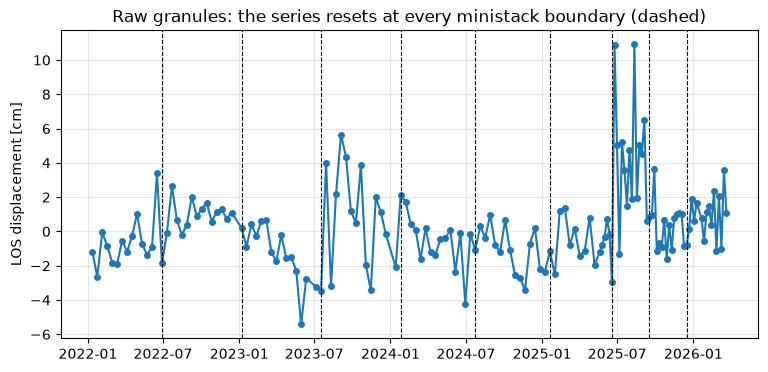

In [13]:
ts_raw = ds_raw.displacement.isel(y=row, x=col).compute()
ref_time = ds_raw.reference_time.compute()

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(ts_raw.time, ts_raw * 100, "o-", ms=4)
for boundary in np.unique(ref_time.values)[1:]:
    ax.axvline(boundary, color="k", ls="--", lw=0.8)
ax.set_ylabel("LOS displacement [cm]")
ax.set_title("Raw granules: the series resets at every ministack boundary (dashed)")
ax.grid(alpha=0.3)

## Rebase into one continuous time series

`opera-utils disp-s1-reformat` does the accumulation and writes a single stack file. It
also handles three related operations:

- **`--reference-method`** picks the *spatial* reference, the pixel (or set of pixels) that is defined to be motionless. `BORDER` uses the median of the edge pixels; `HIGH_COHERENCE` uses the median of everything above a coherence threshold; `POINT` takes a lat/lon you choose. Note this is independent of the *temporal* reference date.
- **corrections**: solid-earth tide is applied by default, ionospheric delay is not. Neither is necessary if your cropped AOI is small (where small is ~under 100km per side)
- **quality masking** while accumulating, via `--quality-datasets`.

`--quality-datasets` decides which pixels get masked *before* accumulating, and it defaults to `RECOMMENDED_MASK`. Masking happens per epoch, and a masked crossover can make a pixel invalid for every later date. On the 2020-2022 portion of this stack:

| reformat settings | valid pixels at the first epoch | at the last |
|---|---|---|
| `RECOMMENDED_MASK` (default) | 97.5% | **57.7%** |
| `--quality-datasets None` | 99.9% | **99.9%** |

Irrigated farmland often decorrelates between passes. In this example, applying the mask during rebasing removes about 40% of the scene by the final date, including the Corcoran pixel used below.

For this exercise we do not mask during rebasing. We retain the source observations and apply the recommended mask during analysis. This lets us experiment with different quality metric thresholds.

Choosing an AOI that includes the urban areas inside the box gives us a choice of stable spatial reference points.

In [14]:
%%bash
time opera-utils disp-s1-reformat \
    --input-files subsets/OPERA*.nc \
    --output-name eastBay-stack.nc \
    --reference-method BORDER \
    --quality-datasets None \
    --drop-vars shp_counts estimated_phase_quality

/opt/miniconda3/envs/opera_app/lib/python3.14/site-packages/opera_utils/disp/_reformat.py:170: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  ds = xr.open_mfdataset(dps.filenames, engine="h5netcdf", chunks=process_chunk_dict)
/opt/miniconda3/envs/opera_app/lib/python3.14/site-packages/opera_utils/disp/_reformat.py:171: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combin

Wrote minimal dataset: <xarray.Dataset> Size: 4MB
Dimensions:                 (time: 150, y: 1102, x: 889)
Coordinates:
  * time                    (time) datetime64[ns] 1kB 2022-01-11T14:08:05.715...
  * y                       (y) float64 9kB 4.212e+06 4.211e+06 ... 4.178e+06
  * x                       (x) float64 7kB 5.526e+05 5.527e+05 ... 5.793e+05
Data variables:
    spatial_ref             (time) int64 1kB 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0
    reference_time          (time) datetime64[ns] 1kB dask.array<chunksize=(1,), meta=np.ndarray>
    water_mask              (y, x) float32 4MB dask.array<chunksize=(1102, 889), meta=np.ndarray>
    perpendicular_baseline  (time) float32 600B dask.array<chunksize=(1,), meta=np.ndarray>
Attributes:
    Conventions:         CF-1.8
    contact:             opera-sds-ops@jpl.nasa.gov
    institution:         NASA JPL
    mission_name:        OPERA
    reference_document:  JPL D-108765
    title:               OPERA_L3_DISP-S1 Product
 in 12.0s


real	1m48.017s
user	1m42.280s
sys	0m5.505s


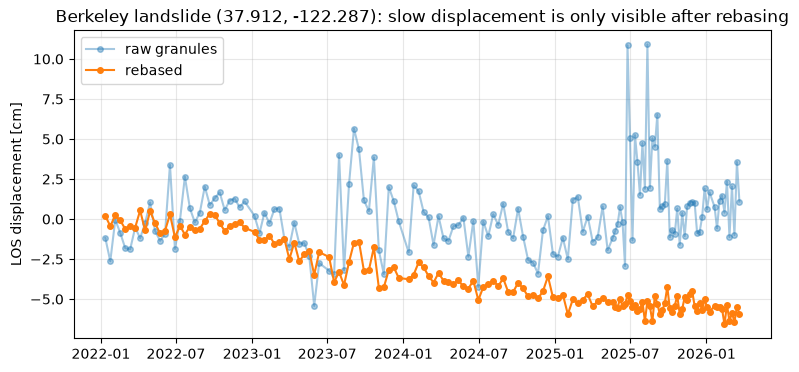

In [15]:
ds = xr.open_dataset("eastBay-stack.nc")
ts = ds.displacement.isel(y=row, x=col)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(ts_raw.time, ts_raw * 100, "o-", ms=4, alpha=0.4, label="raw granules")
ax.plot(ts.time, ts * 100, "o-", ms=4, label="rebased")
ax.set_ylabel("LOS displacement [cm]")
ax.set_title(f"Berkeley landslide ({LAT}, {LON}): slow displacement is only visible after rebasing")
ax.legend()
ax.grid(alpha=0.3)

### Comparing drought years to wet years

Notice the acceleration in the time series during winter 2022-2023.

California had multiple atmospheric rivers that winter, and we can see the landslide movement increased in the time series.

In [16]:
years = (ts.time - ts.time[0]) / np.timedelta64(365, "D")
finite = np.isfinite(ts)

for label, lo, hi in [
    ("2022-01 to 2022-09  (drought)", "2022-01-01", "2022-09-30"),
    ("2022-10 to 2024-05  (after the atmospheric rivers)", "2022-10-01", "2024-06-01"),
]:
    window = (ts.time >= np.datetime64(lo)) & (ts.time < np.datetime64(hi)) & finite
    rate = np.polyfit(years[window], ts[window] * 100, 1)[0]
    print(f"{label}: {rate:6.1f} cm/yr")

2022-01 to 2022-09  (drought):   -0.5 cm/yr
2022-10 to 2024-05  (after the atmospheric rivers):   -2.3 cm/yr


#### The fitted LOS rate is -0.5 cm/yr during the first interval and -2.3 cm/yr during the second. ####
At this pixel, the slow motion (negative in the descending LOS) in early 2022 becomes more rapid in late 2022 and early 2023. That change is consistent with water reaching the slip surface and increasing the pore pressure after the wet 2022-2023 winter. 

## Finding reliable pixels

DISP-S1 includes several quality layers. We use two here:

- `temporal_coherence` (0-1): how well all the interferograms agree with the phase-linking solution. This is *not* MintPy's `temporalCoherence`.
- `phase_similarity` (-1 to 1): median cosine similarity between a pixel and its neighbours. Negative means the pixel disagrees with everything around it.

`recommended_mask` combines those with the water mask and connected-component labels. It is useful for display and screening even though we chose not to apply it during rebasing. 
Users may choose to ignore it to see all noisy pixels and choose their own mask based on longer-term statistics

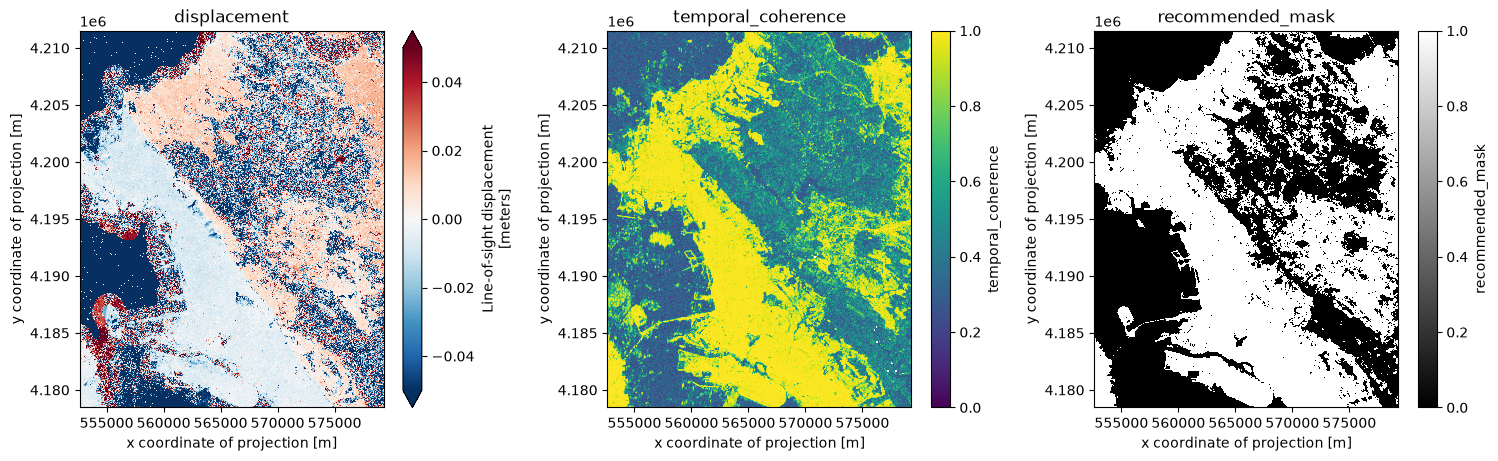

In [17]:
last = ds.isel(time=-1)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)
for ax, name, kw in [
    (axes[0], "displacement", dict(cmap="RdBu_r", vmin=-0.05, vmax=0.05)),
    (axes[1], "temporal_coherence", dict(cmap="viridis", vmin=0, vmax=1)),
    (axes[2], "recommended_mask", dict(cmap="gray", vmin=0, vmax=1)),
]:
    last[name].plot.imshow(ax=ax, **kw)
    ax.set_aspect("equal")
    ax.set_title(name)

## Average velocity

Since we have a single-refernce time series, we can plot an average velocity using `xarray.polyfit`.

In part 2 we use `MintPy` do this instead.

Text(0.5, 1.0, 'Frame 11115 LOS velocity')

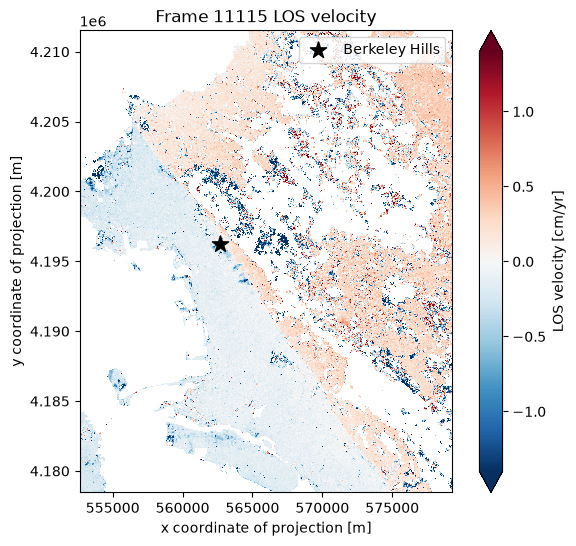

In [18]:
masked = ds.displacement.where(last.recommended_mask == 1)
years = (ds.time - ds.time[0]) / np.timedelta64(365, "D")

fit = masked.assign_coords(time=years).polyfit("time", deg=1)
velocity_cm_yr = fit.polyfit_coefficients.sel(degree=1) * 100

fig, ax = plt.subplots(figsize=(7, 6))
velocity_cm_yr.plot.imshow(
    ax=ax,
    cmap="RdBu_r",
    vmin=-1.4,
    vmax=1.4,
    cbar_kwargs={"label": "LOS velocity [cm/yr]"},
)
ax.scatter(ds.x[col], ds.y[row], marker="*", s=150, c="k", label="Berkeley Hills")
ax.set_aspect("equal")
ax.legend()
ax.set_title(f"Frame {FRAME_ID} LOS velocity")

**Next:** part 2 converts this stack to MintPy format and compares it against the ASF displacement portal.